
# Análise exploratória — Avaliações Olist

Esta análise investiga a qualidade e a estrutura das avaliações de clientes do dataset Olist, com foco na construção da base de conhecimento do sistema RAG.

Serão avaliados a disponibilidade de comentários textuais, a distribuição das notas, o comprimento dos comentários e possíveis duplicidades.


In [19]:

"""Exploratory analysis of the Olist customer reviews dataset."""

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path("../data/raw/olist_order_reviews_dataset.csv")


In [20]:

"""Load customer reviews and inspect the dataset structure."""

reviews = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {reviews.shape}")
display(reviews.head())
reviews.info()


Dataset shape: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB


In [21]:

"""Measure the availability of textual customer reviews."""

has_text = reviews["review_comment_message"].fillna("").str.strip().ne("")

summary = pd.DataFrame({
    "category": ["With text", "Without text"],
    "count": [has_text.sum(), (~has_text).sum()],
})

summary["percentage"] = (
    summary["count"] / len(reviews) * 100
).round(2)

display(summary)


,category,count,percentage
0,With text,40950,41.27
1,Without text,58274,58.73


,All reviews,Reviews with text
review_score,,
1,11424,8744
2,3151,2145
3,8179,3556
4,19142,5970
5,57328,20535


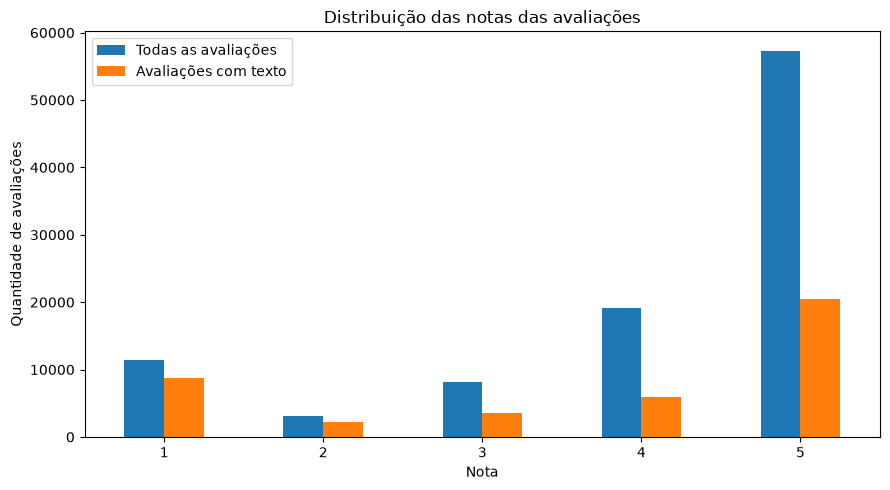

In [22]:

"""Compare review scores in the full dataset and textual reviews."""

score_distribution = pd.DataFrame({
    "All reviews": reviews["review_score"].value_counts().sort_index(),
    "Reviews with text": (
        reviews.loc[has_text, "review_score"]
        .value_counts()
        .sort_index()
    ),
})

display(score_distribution)

score_distribution.columns = [
    "Todas as avaliações",
    "Avaliações com texto",
]

score_distribution.plot(kind="bar", figsize=(9, 5))
plt.title("Distribuição das notas das avaliações")
plt.xlabel("Nota")
plt.ylabel("Quantidade de avaliações")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [23]:

"""Compare the proportion of negative reviews."""

negative = reviews["review_score"].isin([1, 2])

print(f"Negative reviews (all): {negative.mean():.1%}")
print(f"Negative reviews (with text): {negative[has_text].mean():.1%}")


Negative reviews (all): 14.7%
Negative reviews (with text): 26.6%



### Distribuição das avaliações

Das 99.224 avaliações, 40.950 (41,27%) possuem comentários textuais.

Entre as avaliações com texto, aproximadamente 26,6% possuem notas 1 ou 2, enquanto na base completa essa proporção é de aproximadamente 14,7%.

Isso indica que avaliações negativas estão proporcionalmente mais representadas entre os comentários textuais. Portanto, a distribuição das notas da base indexada não deve ser utilizada para representar a satisfação de todos os consumidores.


In [24]:

"""Inspect comment lengths and potential duplicate records."""

text_reviews = reviews.loc[has_text].copy()
text_reviews["comment_length"] = (
    text_reviews["review_comment_message"].str.len()
)

display(
    text_reviews["comment_length"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

duplicate_summary = pd.Series({
    "Duplicate review IDs": reviews["review_id"].duplicated().sum(),
    "Exact duplicate rows": reviews.duplicated().sum(),
    "Duplicate non-empty comments": (
        text_reviews["review_comment_message"].duplicated().sum()
    ),
})

display(duplicate_summary)


count    40950.000000
mean        68.681245
std         53.840130
min          1.000000
50%         53.000000
90%        161.000000
95%        192.000000
99%        200.000000
max        208.000000
Name: comment_length, dtype: float64

Duplicate review IDs             814
Exact duplicate rows               0
Duplicate non-empty comments    4795
dtype: int64

In [25]:

"""Inspect review IDs associated with multiple records."""

duplicates = reviews.loc[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

duplicate_analysis = duplicates.groupby("review_id").agg(
    records=("order_id", "size"),
    unique_orders=("order_id", "nunique"),
    unique_comments=("review_comment_message", "nunique"),
    unique_scores=("review_score", "nunique"),
)

display(duplicate_analysis.describe())
display(duplicates.head(10))


,records,unique_orders,unique_comments,unique_scores
count,789.000000,789.000000,789.000000,789.0
mean,2.031686,2.031686,0.378961,1.0
std,0.175273,0.175273,0.485436,0.0
min,2.000000,2.000000,0.000000,1.0
25%,2.000000,2.000000,0.000000,1.0
50%,2.000000,2.000000,0.000000,1.0
75%,2.000000,2.000000,1.000000,1.0
max,3.000000,3.000000,1.000000,1.0


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [26]:

"""Inspect frequent comments and very short reviews."""

comments = text_reviews["review_comment_message"].str.strip()

print("Most frequent comments:")
display(comments.value_counts().head(20))

short_reviews = text_reviews.loc[comments.str.len() < 10]

print(f"Comments shorter than 10 characters: {len(short_reviews):,}")

display(
    short_reviews[
        ["review_score", "review_comment_message"]
    ].head(20)
)


Most frequent comments:


review_comment_message
Muito bom               305
Bom                     215
Ótimo                   158
Recomendo               153
muito bom               144
bom                     111
otimo                   108
Excelente               108
Otimo                   107
Ok                       78
recomendo                71
Ótimo produto            67
ok                       58
Boa                      55
.                        52
Não recebi o produto     51
Tudo ok                  51
Gostei                   46
Muito bom.               43
excelente                40
Name: count, dtype: int64

Comments shorter than 10 characters: 3,172


,review_score,review_comment_message
19,1,Péssimo
37,5,muito boa
55,5,boa
59,5,MT lindo
80,5,Maravilha
135,3,Gostei
142,5,OTIMA
160,5,OK
189,5,Muito bom
228,5,Recomendo


In [27]:

"""Measure review title availability and inspect examples."""

titles = reviews["review_comment_title"].fillna("").str.strip()
has_title = titles.ne("")

title_summary = pd.Series({
    "Reviews with title": has_title.sum(),
    "Title and comment": (has_title & has_text).sum(),
    "Title without comment": (has_title & ~has_text).sum(),
})

display(title_summary)

display(
    reviews.loc[
        has_title,
        ["review_score", "review_comment_title", "review_comment_message"]
    ].head(15)
)


Reviews with title       11566
Title and comment         9829
Title without comment     1737
dtype: int64

,review_score,review_comment_title,review_comment_message
9,4,recomendo,aparelho eficiente. no site a marca do aparelh...
15,5,Super recomendo,"Vendedor confiável, produto ok e entrega antes..."
19,1,Não chegou meu produto,Péssimo
22,5,Ótimo,Loja nota 10
34,4,Muito bom.,Recebi exatamente o que esperava. As demais en...
36,5,Bom,"Recomendo ,"
38,5,Maravilhoso!,"Tô completamente apaixonada, loja super respon..."
43,5,Entrega perfeita,Muito bom. muito cheiroso.
53,5,Ótimo,NaN
59,5,MT lindo,MT lindo


In [28]:

"""Inspect the date range and yearly review distribution."""

review_dates = pd.to_datetime(
    reviews["review_creation_date"],
    errors="coerce",
)

print(f"First review: {review_dates.min()}")
print(f"Last review: {review_dates.max()}")
print(f"Invalid dates: {review_dates.isna().sum()}")

display(
    review_dates.dt.year.value_counts().sort_index()
)


First review: 2016-10-02 00:00:00
Last review: 2018-08-31 00:00:00
Invalid dates: 0


review_creation_date
2016      325
2017    42735
2018    56164
Name: count, dtype: int64

In [29]:

"""Check whether repeated review IDs have conflicting attributes."""

fields = [
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
    "review_answer_timestamp",
]

consistency = duplicates.groupby("review_id")[fields].nunique(
    dropna=False
)

conflicts = consistency.gt(1).sum()

display(conflicts)

review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

In [30]:

"""Sample customer comments across review scores."""

sample = (
    text_reviews.groupby("review_score", group_keys=False)
    .sample(n=8, random_state=42)
)

display(
    sample[
        ["review_score", "review_comment_title", "review_comment_message"]
    ].sort_values("review_score")
)


,review_score,review_comment_title,review_comment_message
51110,1,N foi entregue ainda,Demora de entrega
83161,1,NaN,"Depois que fiz a compra, passou 30 dias para a..."
35957,1,NaN,"ainda não entregaram meu produto, apenas o out..."
18683,1,NaN,"Não estou satisfeita, pois ainda não recebi o ..."
86257,1,NaN,Até hoje não recebi meu produto. Vou fazer uma...
34700,1,NaN,O produto já passou da data de entrega e não c...
38870,1,NaN,"Até o momento não recebi o produto , não entra..."
16820,1,NaN,Produto veio faltando duas peças e eu pedi a t...
42182,2,NaN,Vieram 2 rastreadores e nenhum dos dois funcio...
34416,2,Gostei,"Recebi o produto certinho, mas quero o reembol..."


In [31]:

"""Inspect comments near the observed maximum length."""

long_comments = text_reviews.loc[
    text_reviews["comment_length"] >= 195,
    ["comment_length", "review_comment_message"]
]

print(f"Comments with at least 195 characters: {len(long_comments):,}")

display(
    long_comments.sort_values(
        "comment_length", ascending=False
    ).head(20)
)


Comments with at least 195 characters: 1,736


,comment_length,review_comment_message
1316,208,"NÃO RECEBI O PRODUTO, O PRODUTO CONSTA COMO EN..."
10734,207,Adquiri 2 mochilas pelo site lannister de e pa...
7267,206,Comprei o produto confiando nas lojas lanniste...
5223,205,fiz essa compra pelo baratheon comprei um conj...
60442,204,Recebi a mercadoria errada.\r\nComprei o chuve...
60390,204,RECEBI UM PRODUTO F-A-L-S-I-F-I-C-A-D-O. Ñ SAB...
77260,204,Não Montei ele ainda mais pelo que conferi est...
52573,204,assim que fiz o pedido observei que tinha pedi...
33455,204,A EMPRESA FAZ PROPAGANDA ENGANOSA EM SEU SITE....
12824,204,"A empresa terceira targaryen não é confiavel, ..."


In [32]:

"""Count unique reviews with usable textual content."""

has_content = has_text | has_title

eligible_reviews = reviews.loc[has_content]

print(f"Eligible rows: {len(eligible_reviews):,}")
print(f"Unique reviews: {eligible_reviews['review_id'].nunique():,}")
print(f"Repeated rows to consolidate: {len(eligible_reviews) - eligible_reviews['review_id'].nunique():,}")


Eligible rows: 42,687
Unique reviews: 42,370
Repeated rows to consolidate: 317


In [33]:

"""Inspect the endings of comments near the maximum length."""

long_comments = text_reviews.loc[
    text_reviews["comment_length"] >= 195,
    "review_comment_message",
]

display(
    pd.DataFrame({
        "length": long_comments.str.len(),
        "ending": long_comments.str[-40:],
    }).head(30)
)


,length,ending
115,203,"rianças 1 un - R$ 35,90 (ESTE FOI ENTREG"
212,199,suspense terminou mas lá não compro mais
227,199,m chegar antes do prazo. Estranhei muito
253,195,guitarra e acessórios estavam corretos.
332,200,com defeito e até agora não me deu retor
361,196,"tá funcionando ou não, ainda não testei."
382,202,Quase um mês para entregar. Extra.com ok
419,204,dutos que foram pagos com boleto bancari
646,200,ução e análise para ter meuressarcimento
711,199,"endo que tem despesa para devoluçao, por"


In [34]:
"""Measure titles repeated at the beginning of review comments."""

SEPARATORS = (" ", ",", ".", "!", "?", ":", ";")


def normalize_value(value: object) -> str:
    """Normalize whitespace and handle missing text."""
    if pd.isna(value):
        return ""
    return " ".join(str(value).split())


def has_letters(text: str) -> bool:
    """Check whether the text contains at least one Unicode letter."""
    return any(char.isalpha() for char in text)


def is_repeated_prefix(title: str, comment: str) -> bool:
    """Apply the same rule used by build_document in the pipeline."""
    if not has_letters(title) or not comment:
        return False

    prefix = title.rstrip(".,!?;: ").casefold()
    key = comment.casefold()

    return key == prefix or any(
        key.startswith(prefix + separator) for separator in SEPARATORS
    )


def is_repeated_prefix_legacy(title: str, comment: str) -> bool:
    """Previous rule, without trailing punctuation handling."""
    if not title or not comment:
        return False

    prefix = title.casefold()
    key = comment.casefold()

    return key == prefix or any(
        key.startswith(prefix + separator) for separator in (" ", ",", ".", "!")
    )


titles = reviews["review_comment_title"].map(normalize_value)
comments = reviews["review_comment_message"].map(normalize_value)

repeated_prefix = [
    is_repeated_prefix(title, comment)
    for title, comment in zip(titles, comments)
]
repeated_legacy = [
    is_repeated_prefix_legacy(title, comment)
    for title, comment in zip(titles, comments)
]

print(f"Repeated title prefixes (pipeline rule): {sum(repeated_prefix):,}")
print(f"Repeated title prefixes (previous rule): {sum(repeated_legacy):,}")

display(
    reviews.loc[
        repeated_prefix,
        ["review_comment_title", "review_comment_message"],
    ].head(15)
)

Repeated title prefixes (pipeline rule): 575
Repeated title prefixes (previous rule): 561


,review_comment_title,review_comment_message
59,MT lindo,MT lindo
671,Muito bom o produto,"Muito bom o produto, melhor que esperava e foi..."
740,Entrega antes do prazo.,"Entrega antes do prazo, recomendo essa loja."
934,Comprei 2 produtos,Comprei 2 produtos so mandaram 1 e n mim deram...
1384,Satisfeito,Satisfeito
1592,X,X
1598,Ótimo produto!,"Ótimo produto, entrega muito rápida!"
1628,BOA LOJA,"BOA LOJA, CUMPRIU TUDO O QUE ESTAVA NO ANUNCIO..."
1716,Produto veio diferente,Produto veio diferente ao anuncuado. Liguei e ...
2061,Ok,Ok


In [35]:

"""Inspect repeated normalized texts and document lengths."""

prepared = pd.read_csv("../data/processed/olist_reviews_clean.csv")

print("Most frequent deduplication keys:")
display(prepared["dedup_key"].value_counts().head(20))

print("\nDocument length distribution:")
display(
    prepared["n_chars"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

print(f"Documents shorter than 10 characters: {(prepared['n_chars'] < 10).sum():,}")
print(f"Duplicate deduplication keys: {prepared['dedup_key'].duplicated().sum():,}")


Most frequent deduplication keys:


dedup_key
otimo                         601
muito bom                     590
bom                           454
recomendo                     440
excelente                     283
super recomendo               158
ok                            151
otimo produto                 143
otima                         130
boa                           126
tudo ok                       116
nao recebi o produto          114
tudo certo                     85
gostei                         77
entrega rapida                 73
bom produto                    73
gostei muito                   57
adorei                         56
chegou antes do prazo          56
ainda nao recebi o produto     51
Name: count, dtype: int64


Document length distribution:


count    42138.000000
mean        69.076083
std         54.736930
min          1.000000
50%         54.000000
90%        162.000000
95%        193.000000
99%        209.000000
max        228.000000
Name: n_chars, dtype: float64

Documents shorter than 10 characters: 3,536
Duplicate deduplication keys: 7,347


## Conclusões e decisões técnicas

A análise exploratória fundamentou as decisões de preparação da base RAG. O notebook mede o universo bruto; o pipeline (`src/prepare_data.py`) aplica as regras finais. Por isso, as contagens abaixo aparecem em duas etapas.

### Reconciliação das contagens

| Etapa | Registros | Fonte |
|---|---:|---|
| Base original | 99.224 | EDA |
| Com título ou comentário não vazio | 42.687 | EDA |
| Elegíveis após descartar títulos sem letras | 42.588 | Pipeline |
| Avaliações únicas (`review_id`) | 42.272 | Pipeline |
| Documentos sem letras excluídos | 134 | Pipeline |
| **Documentos finais** | **42.138** | Pipeline |

A diferença entre 42.687 e 42.588 (99 registros) corresponde a avaliações cujo único conteúdo era um título sem letras, como "3". Essas avaliações deixam de ter texto utilizável quando o título é descartado.

### Decisões

- **Seleção textual:** utilizar avaliações com título ou comentário não vazio. Foram identificados 40.950 comentários não vazios e 1.737 registros com apenas título.
- **Valores ausentes:** desconsiderar campos vazios, incluindo 27 comentários compostos apenas por espaços.
- **Duplicidades por identificador:** consolidar registros com o mesmo `review_id`, preservando os pedidos associados em `order_ids`. Não há divergência de nota, título, comentário ou datas entre eles.
- **Construção do documento:**
  - descartar títulos sem letras;
  - usar apenas o comentário quando o título for igual a ele ou aparecer no início dele (575 casos medidos na EDA);
  - concatenar título e comentário nos demais casos.
- **Textos curtos:** excluir documentos sem letras e preservar os demais. Há 3.536 documentos com menos de 10 caracteres (8,4%), registrados em `n_chars`.
- **Textos repetidos:** manter avaliações distintas com texto igual. Foram encontradas 7.347 ocorrências adicionais de chaves normalizadas repetidas (17,4%), tratadas na recuperação com a chave auxiliar `dedup_key`.
- **Metadados:** `review_id`, `order_ids`, `review_score`, `review_creation_date`, `n_chars` e `dedup_key`.
- **Chunking:** indexar cada avaliação como um único documento (mediana de 54 caracteres e máximo de 228).

### Limitações

- **Representatividade:** as notas 1 e 2 correspondem a 14,7% de todas as avaliações e a 26,6% das avaliações com comentário. A base textual não representa proporcionalmente a satisfação de todos os consumidores.
- **Interpretação das notas:** a nota é um indicador aproximado. Notas baixas não garantem que o texto contenha uma reclamação, e notas altas não impedem críticas.
- **Comentários repetidos:** textos genéricos ("Ótimo", "Muito bom", "Recomendo") concentram muitas ocorrências e exigem controle de redundância na recuperação.
- **Possível truncamento:** comentários próximos de 200 caracteres terminam em palavras interrompidas. Isso sugere truncamento na origem, sem comprovar a regra aplicada. Os textos são preservados sem reconstrução.
- **Período:** os registros abrangem outubro de 2016 a agosto de 2018. `review_creation_date` é a data de envio da pesquisa de satisfação, não a data da compra.
- **Anonimização:** nomes como "lannister", "targaryen" e "baratheon" são fictícios e não representam lojas reais.

### Reprodutibilidade

Ordem de execução:

1. Executar `python -m src.download_data` para gerar `data/raw/olist_order_reviews_dataset.csv`.
2. Executar `python -m src.prepare_data` para gerar `data/processed/olist_reviews_clean.csv`.
3. Executar este notebook. A última análise lê o arquivo processado.
4. Executar `python -m pytest -q` (20 testes).